# Preprocessing

Le but de ce notebook est de travailler la donnée issue des verbatims pour pouvoir mener une analyse sémantique la plus riche possible.

Nous passerons donc :
- Par la création de colonnes qui regroupent certaines notes en catégories (3)
- Par l'identification de signaux dans les verbatims (points d'exclamations et mots écrits en lettre CAPITALES)
- Par le nettoyage des mots inutiles et de la ponctuation
- Par la lemmatisation, soit le regroupement des mots qui ont une même racine (ex : trouver, trouve --> 1 seul mot).

Dans un autre notebook, nous pourrons mener l'analyse sémantique (NLP), en essayant le BagOfWord, le TD-IDF, le N-series et ensuite le LDA pour regarder quelles mots / thématiques ressortent le plus par série et par niveau de satisfaction.

Par simplicité, nous ne garderons que les verbatims de Imdb, car en langue anglaise, et parce qu'il y en a nettement plus.

In [16]:
# Import des libraires

# Manipulation des données et visualisation
import pandas as pd, numpy as np, re, os
import seaborn as sns
import matplotlib.pyplot as plt

# Natural Language Processing (NLP)
from nltk.corpus import stopwords
from nltk.tokenize import RegexpTokenizer
from nltk.stem import WordNetLemmatizer
from afinn import Afinn
import string

In [17]:
# Import du dataframe
df = pd.read_csv("../data/data_clean.csv")
df.head()

,notes,avis,dates,series,allocine_id,review_id,plateforme
0,4,Seule le format est décevant. Seulement 6 épis...,2026-02-08,A Knight of the Seven Kingdoms,28230,282301,Allocine
1,5,Très bonne série. Des épisodes trop court tr...,2026-02-07,A Knight of the Seven Kingdoms,28230,282302,Allocine
2,5,J’y ai trouvé du génie ! Pour ceux qui disent ...,2026-02-07,A Knight of the Seven Kingdoms,28230,282303,Allocine
3,5,J'en suis au 4ème épisode et pour l'instant j'...,2026-02-06,A Knight of the Seven Kingdoms,28230,282304,Allocine
4,5,"Encore un grand cru, un bijoux, du caviar, ou ...",2026-02-10,A Knight of the Seven Kingdoms,28230,282305,Allocine


## 1. Ajout de colonnes

Enregistrement des informations les plus importantes : le regroupement de notes en 3 catégories, les métadonnées et le score de Sentiment.

In [18]:
# Création des fonctions pour créer des regroupements de la note (en 3 catégories)
def notes_3_cat(value):
    if value < 4:
        return -1
    elif 4 <= value < 7:
        return 0
    else:
        return 1

# Création des colonnes
df['notes_3'] = df['notes'].map(notes_3_cat)

In [19]:
# Vérification des effectifs de notes par série
for serie in df['series'].unique():
    print(f'Distribution des notes de la série {serie} : \n', df[df['series'] == serie]['notes_3'].value_counts())
    print()

# Des échantillons suffisants pour les catégories de notes des deux séries.

Distribution des notes de la série A Knight of the Seven Kingdoms : 
 notes_3
 0    97
-1    68
Name: count, dtype: int64

Distribution des notes de la série King & Conqueror : 
 notes_3
-1    27
 0     7
Name: count, dtype: int64



In [20]:
# Création des fonctions
def capital_count(text : str):
    '''Compter le nombre de mots écrits en lettres capitales dans un texte'''
    capital = re.compile(r'[A-Z]{2,}')
    capital_search = capital.findall(text)
    return len(capital_search)

def exclamation_count(text : str):
    '''Compter le nombre de points d'exclamation dans un texte'''
    exclamation = re.compile(r'!')
    exclamation_search = exclamation.findall(text)
    return len(exclamation_search)

def exclamation_chain_count(text : str):
    '''Compter le nombre de chaînes de points d'exclamation (!!!) dans un texte'''
    exclamation_chain = re.compile(r'[!]{2,}')
    exclamation_chain_search = exclamation_chain.findall(text)
    return len(exclamation_chain_search)

def interrogation_count(text : str):
    '''Compter le nombre de points d'interrogation dans un texte'''
    interrogation = re.compile(r'\?')
    interrogation_search = interrogation.findall(text)
    return len(interrogation_search)

def interrogation_chain_count(text : str):
    '''Compter le nombre de chaînes de points d'exclamation (!!!) dans un texte'''
    interrogation_chain = re.compile(r'[?]{2,}')
    interrogation_chain_search = interrogation_chain.findall(text)
    return len(interrogation_chain_search)

# Création des colonnes de métadonnées
df['nb_capital_words'] = df['avis'].apply(capital_count)
df['nb_exclamation_points'] = df['avis'].apply(exclamation_count)
df['nb_exclamation_points_chains'] = df['avis'].apply(exclamation_chain_count)
df['nb_interrogation_points'] = df['avis'].apply(interrogation_count)
df['nb_interrogation_points_chains'] = df['avis'].apply(interrogation_chain_count)
df['lenght'] = df['avis'].apply(len)

In [21]:
df.describe()

,notes,allocine_id,review_id,notes_3,nb_capital_words,nb_exclamation_points,nb_exclamation_points_chains,nb_interrogation_points,nb_interrogation_points_chains,lenght
count,199.000000,199.000000,1.990000e+02,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000
mean,3.206030,29489.879397,1.673541e+07,-0.477387,0.412060,0.693467,0.105528,0.175879,0.005025,588.170854
std,1.679575,2782.437581,1.433399e+07,0.500748,0.882521,1.501349,0.486089,0.598163,0.070888,1130.090066
min,0.000000,28230.000000,2.823010e+05,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,72.000000
25%,2.000000,28230.000000,2.823050e+06,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,189.000000
50%,4.000000,28230.000000,2.823010e+07,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,335.000000
75%,5.000000,28230.000000,2.823015e+07,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,629.500000
max,5.000000,35604.000000,3.560420e+07,0.000000,6.000000,10.000000,5.000000,4.000000,1.000000,13977.000000


In [22]:
# Regardons directement les commentaires qui ont des métadonnées supérieures à 1.
# Nous traiterons le cas de 'length' différemment

df_metadonnees = df[['nb_capital_words', 'nb_exclamation_points', 'nb_exclamation_points_chains', \
                     'nb_interrogation_points', 'nb_interrogation_points_chains']]

for col in df_metadonnees:
    print(col, ' :')
    display(df[['avis', 'notes_3']][df_metadonnees[col] >= 1])
    print() # Saut de ligne

nb_capital_words  :


,avis,notes_3
0,Seule le format est décevant. Seulement 6 épis...,0
11,Ce que j’aime profondément dans *A Knight of t...,0
13,"Plus léger que GOT. Un univers soigné, une pho...",0
15,Quel bonheur cette comédie des petites gens lo...,0
17,Après le gigantisme de Game of Thrones et les ...,-1
18,"Quelle nouvelle masterclass d’HBO , l’univers ...",0
19,Bien que souhaitant noter cette série une fois...,0
20,"Une grande série a venir, des personnages haut...",0
28,Si HBO nous avait habitué à tenir la dragée ha...,-1
31,"Pffff que dire ? C´est fade, pas grand chose à...",-1



nb_exclamation_points  :


,avis,notes_3
0,Seule le format est décevant. Seulement 6 épis...,0
2,J’y ai trouvé du génie ! Pour ceux qui disent ...,0
4,"Encore un grand cru, un bijoux, du caviar, ou ...",0
7,"3 épisodes sont passés, ça me parait assez pou...",0
12,Une série qui reçoit globalement que des éloge...,-1
14,"Un des meilleurs premiers épisodes de série, d...",0
16,Au delà du très bon scénario de début (3 épiso...,0
27,J'adore tout simplement !Moi qui n'ai pas trop...,0
30,Magnifique ! Cette série est prenante dès le d...,0
33,un style différent. plus lent plus un conte et...,0



nb_exclamation_points_chains  :


,avis,notes_3
12,Une série qui reçoit globalement que des éloge...,-1
30,Magnifique ! Cette série est prenante dès le d...,0
33,un style différent. plus lent plus un conte et...,0
34,"Après 3 épisodes pour poser l'intrigue, cette ...",0
43,"Tout bonnement exceptionnelle, l’écriture est ...",0
53,"Je ne suis pas très fan du côté ridicule, même...",0
54,Les 4 premiers épisodes sont vraiment excellen...,0
63,spoiler:Une bonne surpriseavec cette nouvell...,-1
84,Perplexe devant cette série et devant les crit...,-1
118,Très bien !! ( saison 1 )Cette première saison...,0



nb_interrogation_points  :


,avis,notes_3
7,"3 épisodes sont passés, ça me parait assez pou...",0
17,Après le gigantisme de Game of Thrones et les ...,-1
24,Désolé pour ceux qui encensent cette daube mai...,-1
29,"Quelle déception, j’en suis au 3 ème épisode e...",-1
31,"Pffff que dire ? C´est fade, pas grand chose à...",-1
36,Tellement ennuyeux ! Quel intérêt de voir un c...,-1
41,Après la très lourde et ratée et désavouée par...,0
60,"Que dire ? Après ""Game of Thrones"" et ""House o...",0
72,Cette nouvelle série dérivée de l'univers de G...,-1
77,Mais sérieusement d'où sort l'acteur principal...,-1



nb_interrogation_points_chains  :


,avis,notes_3
173,Encore une fois le réalisateur écrit sa propre...,-1


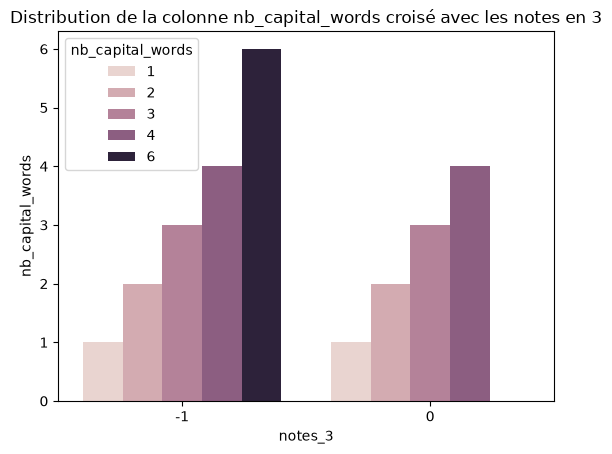

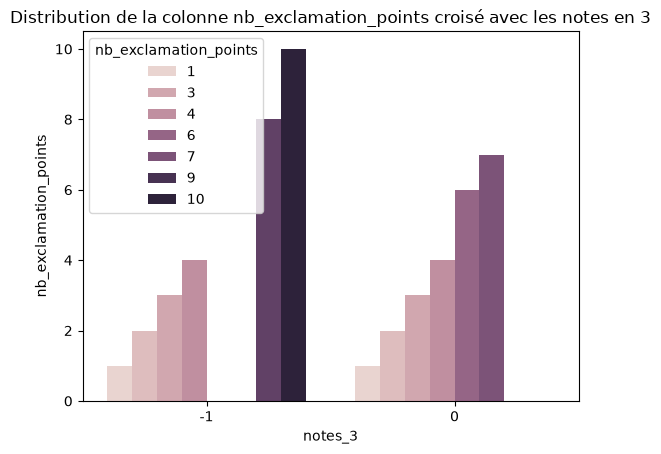

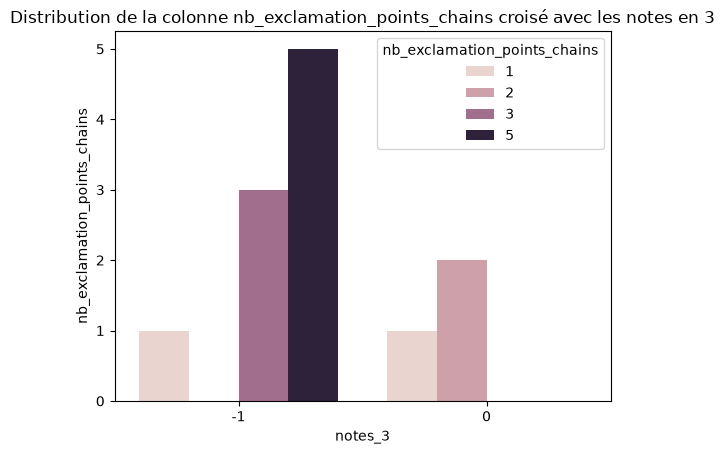

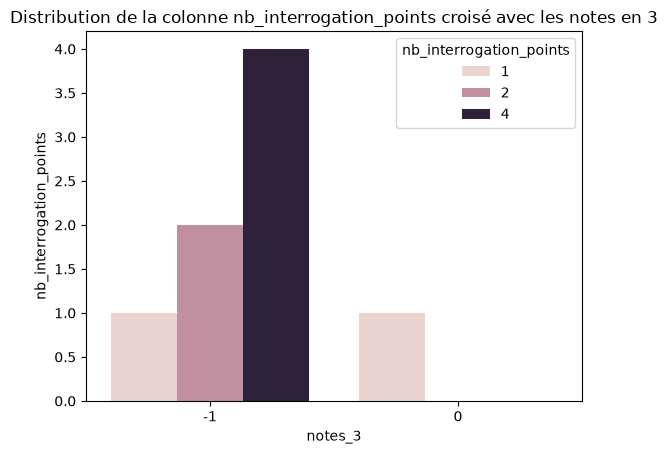

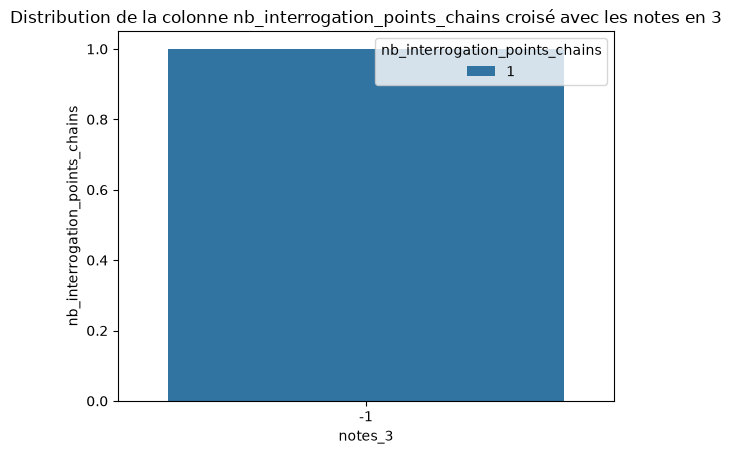

In [23]:
# Analysons l'impact des métadonnées lorsqu'elle sont au moins égales à 1
for col in df_metadonnees:
    sns.barplot(data=df[df[col] >=1], x='notes_3', \
                y=col, hue=col)
    plt.title(f'Distribution de la colonne {col} croisé avec les notes en 3')
    plt.show()

Enseignements :
- La présence de mots en lettre capitale semble corrélé positivement avec les notes positives. Surtout lorsqu'il y en a au moins 50 dans un même avis.
- Les points d'exclamation intensifient les avis : on les trouve davantage où il y a des notes positives et négatives. Lorsqu'il y en a plus de 15, c'est un signe que la note est positive.
- A l'inverse, les points d'interrogration semblent davantage présent pour mettre en cause la série, surtout lorsqu'il y en a beaucoup (10 ou plus)

## 2. Nettoyage

Dans cette section, nous allons retirer les mots inutiles et la ponctuation.

In [ ]:
from itertools import permutations
import spacy

Exception ignored in: <function WeakKeyDictionary.__init__.<locals>.remove at 0x000001EFFB10C900>
Traceback (most recent call last):
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\Lib\weakref.py", line 370, in remove
    self = selfref()
KeyboardInterrupt: 


In [ ]:
# Configuration
INPUT_FILE = "export_powerbi.csv"
OUTPUT_FILE = "tokens_powerbi.csv"

# Séparateur du CSV — Power BI exporte souvent en ";" en français (Excel FR),
# mais parfois en "," selon la config régionale. A vérifier/ajuster.
CSV_SEPARATEUR = ";"
CSV_ENCODAGE = "utf-8-sig"  # utf-8-sig gère le BOM ajouté par Excel/Power BI à l'export

# Noms des colonnes dans votre export Power BI — à ajuster si différents
COL_ID_UNIQUE = "ID-Axe"
COL_AXE = "Axe"
COL_COMMENTAIRE = "Commentaire"

# Dictionnaire de synonymes / normalisation lexicale.
# clé   = terme brut lemmatisé (unigramme ou bigramme, tel qu'il sortira de la lemmatisation)
# valeur = terme normalisé que vous voulez afficher dans les visuels regroupés
#
# ATTENTION : ne fusionnez pas des marques et des catégories génériques
# si vous voulez pouvoir les distinguer plus tard (ex: "iphone" vs "telephone").
SYNONYMES = {
    "smartphone": "téléphone",
    "telephone portable": "téléphone",
    "telephone": "téléphone",
    "téléphone portable" : "téléphone",
    "logiciel": "application",
    "pas bien": "insatisfaisant",
    "mauvais": "insatisfaisant",
    "nul": "insatisfaisant",
    "non compétent" : "insatisfaisant",
    "non satisfaire" : "insatisfaisant",
    "non satisfaisant" : "insatisfaisant",
    "non satisfait" : "insatisfaisant",
    "bien": "satisfaisant",
    "excellent": "très satisfait",
    "satisfait" : "satisfaisant",
    "problème non" : "satisfaisant",
    "non satisfait" : "insatisfaisant",
    "terrible non" : "insatisfaisant",
    "rame" : "lent",
    "non performante" : "lent",
    "top": "très satisfait",
    "bon": "satisfaisant",
    "outil métier" : "application",
    "application métier" : "application",
    "team" : "teams",
    "kiosque" : "komptoir",
    "copilote" : "copilot",
    "metier" : "métier"
}

# Stopwords additionnels métier, en plus des stopwords standards de spaCy
STOPWORDS_SUPPLEMENTAIRES = {"tres", "assez", "plutot", "vraiment", "quand", "meme", "fait", "trop", "que"}

# Longueur minimale (en caractères) d'un lemme pour être conservé
LONGUEUR_MIN_LEMME = 3

# Nombre de termes les plus fréquents à conserver pour la table de paires
# (limite le volume — mettre None pour ne pas filtrer, déconseillé sur gros volumes)
TOP_N_TERMES = 200

In [ ]:
nlp = spacy.load("fr_core_news_sm")

def nettoyer_texte(texte: str) -> str:
    """Minuscule, suppression ponctuation/chiffres, espaces multiples."""
    if not isinstance(texte, str):
        return ""
    texte = texte.lower()
    texte = re.sub(r"[^a-zàâäéèêëïîôöùûüç\s-]", " ", texte)
    texte = re.sub(r"\s+", " ", texte).strip()
    return texte

def lemmatiser_et_filtrer(texte: str) -> list:
    """
    Tokenise + lemmatise avec spaCy, retire stopwords, ponctuation,
    mots vides métier et tokens trop courts.
    Retourne une liste ORDONNEE de lemmes (base pour unigrammes ET bigrammes).
    """
    texte_propre = nettoyer_texte(texte)
    if not texte_propre:
        return []

    doc = nlp(texte_propre)
    lemmes = []
    for token in doc:
        if token.is_stop or token.is_punct or token.is_space:
            continue
        lemme = token.lemma_.strip()
        if len(lemme) < LONGUEUR_MIN_LEMME:
            continue
        if lemme in STOPWORDS_SUPPLEMENTAIRES:
            continue
        lemmes.append(lemme)
    return lemmes

def extraire_bigrams(lemmes: list) -> list:
    """Bigrammes contigus construits à partir de la liste de lemmes déjà filtrée."""
    return [f"{lemmes[i]} {lemmes[i + 1]}" for i in range(len(lemmes) - 1)]


def normaliser(terme: str) -> str:
    """Applique le dictionnaire de synonymes. Retourne le terme brut si absent du dictionnaire."""
    return SYNONYMES.get(terme, terme)



In [ ]:
# Construction des tables

def construire_table_tokens(df: pd.DataFrame) -> pd.DataFrame:
    lignes = []
    for _, row in df.iterrows():
        lemmes = lemmatiser_et_filtrer(row[COL_COMMENTAIRE])

        for lemme in lemmes:
            lignes.append({
                "ID_unique": row[COL_ID_UNIQUE],
                "Axe": row[COL_AXE],
                "terme_brut": lemme,
                "terme_normalise": normaliser(lemme),
                "type": "unigramme",
            })

        for bigram in extraire_bigrams(lemmes):
            lignes.append({
                "ID_unique": row[COL_ID_UNIQUE],
                "Axe": row[COL_AXE],
                "terme_brut": bigram,
                "terme_normalise": normaliser(bigram),
                "type": "bigramme",
            })

    return pd.DataFrame(lignes)

def construire_table_paires(df_tokens: pd.DataFrame, top_n: int = None) -> pd.DataFrame:
    """
    Génère une ligne par paire de termes distincts co-apparaissant dans un même
    ID_unique (terme_normalise). Si top_n est renseigné, ne conserve que les
    top_n termes les plus fréquents avant de générer les paires (réduit le volume).
    """
    if top_n is not None:
        top_termes = (
            df_tokens["terme_normalise"]
            .value_counts()
            .head(top_n)
            .index.tolist()
        )
        # Conserve uniquement les tokens issus des TopN termes choisis.
        df_tokens = df_tokens[df_tokens["terme_normalise"].isin(top_termes)]
 
    lignes = []
    for id_unique, groupe in df_tokens.groupby("ID_unique"):
        termes_distincts = groupe["terme_normalise"].dropna().unique().tolist()
        for terme1, terme2 in permutations(termes_distincts, 2):
            lignes.append({
                "ID_unique": id_unique,
                "terme1": terme1,
                "terme2": terme2,
            })
    return pd.DataFrame(lignes)

In [ ]:
df = pd.read_csv(INPUT_FILE, sep=CSV_SEPARATEUR, encoding=CSV_ENCODAGE)
df[COL_COMMENTAIRE] = df[COL_COMMENTAIRE].apply(corriger_mojibake) # Correction des caractères Ã©

df_tokens = construire_table_tokens(df)
df_tokens.to_csv(OUTPUT_FILE, sep=CSV_SEPARATEUR, encoding=CSV_ENCODAGE, index=False)

df_paires = construire_table_paires(df_tokens, top_n=TOP_N_TERMES)
df_paires.to_csv(OUTPUT_FILE_PAIRES, sep=CSV_SEPARATEUR, encoding=CSV_ENCODAGE, index=False)


print(f"Terminé : {OUTPUT_FILE}")
print(f" - Tokens : {len(df_tokens)} lignes")
print(f" - {OUTPUT_FILE_PAIRES} : {len(df_paires)} lignes (top {TOP_N_TERMES} termes)")

In [ ]:
# Si ces fichiers ne sont pas téléchargés, retirer les #, puis les remettre.
# nltk.download('stopwords')
# nltk.download('punkt')
# nltk.download('punkt_tab')

# Text test
text = "This is a sample sentence showing stopword removal."

# Fonction pour retirer les mots inutiles en anglais
def preprocess_verbatim(verbatim):
    '''Tokenize les mots de chaque verbatim en retirant les mots inutiles et la ponctuation'''
    
    stop_words = set(stopwords.words('english')) # Liste des mots inutiles à retirer.

    verbatim = verbatim.lower()             # Tous les mots en minuscule
    tokenizer = RegexpTokenizer(r'\w+')     # Fonction de tokenisation en retirant la ponctuation.
    tokens = tokenizer.tokenize(verbatim)   # Tokenisation

    filtered_words = [word for word in tokens if word not in stop_words]    # Filtrage des mots inutiles
    return " ".join(filtered_words) # 

# Création de la colonne avec les tokens.
df['tokens'] = df['avis'].apply(preprocess_verbatim)
df['tokens']


210     honest opinion turns westeros way interesting ...
211     far good screw first episode knight seven king...
212     proper return westeros stayed 3 uk premiere on...
213     disappointment ep 1 42 minuts expected hour ho...
214     really freaking good one bad moment far knight...
                              ...                        
1617    mediocre filmmaking weak script combination we...
1618    drunk history many reviewers noted events noth...
1619                                                  get
1620    realism earl military crews count 5 8 soldiers...
1621    historical inaccuracies historical inaccuracie...
Name: tokens, Length: 1412, dtype: str

## 3. Lemmatisation

Nous ferons de la lemmatisation pour conserver la racine de chaque mot, que ce soit un verbe ou un nom.

Dans un prochain notebook, nous pourrons nous concentrer sur le coeur de l'analyse sémantique. nous testerons différentes techniques de tokenisation pour déceler les catégories qui ressortent le plus.

In [ ]:
# Si ces fichiers ne sont pas téléchargés, retirer les #, puis les remettre.
# nltk.download('wordnet')

# Initialisation du lemmatiseur
wordnet_lemmatizer = WordNetLemmatizer()

def lemmatisation(text):
    
    words = re.findall(r'\w+', text) # Liste des mots (sinon itère sur les lettres...)
    lemmatized = [wordnet_lemmatizer.lemmatize(word) for word in words]
    return " ".join(lemmatized)

df['tokens_lemmatized'] = df['tokens'].apply(lemmatisation)

# Peut l'intégrer à la fonction précédente.


In [ ]:
# Vérification
test_words = re.findall(r'\w+', df['tokens'].iloc[0])
for w in test_words:
    print(f"{w} → {wordnet_lemmatizer.lemmatize(w)}")

# On voit à 'dragon' que la lemmatisation a fonctionnée. 

honest → honest
opinion → opinion
turns → turn
westeros → westeros
way → way
interesting → interesting
exploding → exploding
every → every
five → five
minutes → minute
dragons → dragon
throne → throne
drama → drama
one → one
well → well
meaning → meaning
idiot → idiot
sword → sword
kid → kid
clearly → clearly
smarter → smarter
everyone → everyone
else → else
slower → slower
quieter → quieter
somehow → somehow
heart → heart
epic → epic
fantasy → fantasy
like → like
honor → honor
bad → bad
decisions → decision
consequences → consequence
actually → actually
matter → matter
one → one
delivers → delivers
surprisingly → surprisingly
wholesome → wholesome


In [ ]:
# Export en csv
# Un point = dossier actuel, deux points = dossier parent
output_path = '../data/data_preprocessed.csv'
os.makedirs(os.path.dirname(output_path), exist_ok=True)
df.to_csv(output_path, index=False)